# Modern External Dataset
## Six-Model Comparison

**Goal:** Compare the untouched external-test results of the **three TF-IDF** classifiers and **three sentence-transformer embedding** classifiers on the same 600 modern responses (150 human, 150 each ChatGPT/Claude/Gemini).

**This notebook reads the CSV exports from `tfidf_external_evaluation.ipynb` and `embeddings_external_evaluation.ipynb`.

Run **Section 8 (exports)** in *both* evaluation notebooks before running this one. The exact filenames are checked below. Keep this external dataset as a held-out benchmark: interpret results rather than optimizing hyperparameters or thresholds against it.

## 1. Imports and paths

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents]
                     if (p / 'models').is_dir() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter from inside the Spot-the-Bot repository.')
RESULTS_DIR = PROJECT_ROOT / 'data' / 'evaluation'

files = {
    'TF-IDF metrics': RESULTS_DIR / 'modern_tfidf_metrics.csv',
    'Embeddings metrics': RESULTS_DIR / 'modern_embeddings_metrics.csv',
    'TF-IDF predictions': RESULTS_DIR / 'modern_tfidf_predictions.csv',
    'Embeddings predictions': RESULTS_DIR / 'modern_embeddings_predictions.csv',
    'TF-IDF generator metrics': RESULTS_DIR / 'modern_tfidf_generator_metrics.csv',
    'Embeddings generator metrics': RESULTS_DIR / 'modern_embeddings_generator_metrics.csv',
}
missing = [str(path) for path in files.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        'Missing evaluation outputs. Run Section 8 in each evaluation notebook first:\n' +
        '\n'.join(missing)
    )
print('Project root:', PROJECT_ROOT)
print('Using existing CSV exports from:', RESULTS_DIR)


Project root: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text
Using existing CSV exports from: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation


## 2. Load and validate the six model results

Expect exactly three TF-IDF models and three embedding models. If this fails, check the saved model files and rerun the appropriate evaluation notebook.

In [2]:
tfidf_metrics = pd.read_csv(files['TF-IDF metrics'])
embedding_metrics = pd.read_csv(files['Embeddings metrics'])
required_metrics = {'model', 'accuracy', 'macro_precision', 'macro_recall',
                    'macro_f1', 'roc_auc', 'human_false_positive_rate'}
for family, df in [('TF-IDF', tfidf_metrics), ('Embeddings', embedding_metrics)]:
    assert required_metrics.issubset(df.columns), f'{family} missing metrics columns'
    assert len(df) == 3, f'{family}: expected 3 models, found {len(df)}'
    assert df['model'].nunique() == 3, f'{family}: duplicate model names'

metrics = pd.concat([tfidf_metrics, embedding_metrics], ignore_index=True)
assert metrics['model'].nunique() == 6, 'Expected six unique model names'
metrics.insert(1, 'feature_type', np.where(metrics['model'].str.startswith('TF-IDF'),
                                           'TF-IDF', 'Embeddings'))
metrics = metrics.sort_values(['feature_type', 'model']).reset_index(drop=True)
assert metrics.select_dtypes(include='number').notna().all().all(), 'Missing numeric metric values'
display(metrics.round(4))


,model,feature_type,accuracy,macro_precision,macro_recall,macro_f1,roc_auc,human_false_positive_rate
0,Embeddings FFNN,Embeddings,0.3183,0.5093,0.5056,0.3081,0.5376,0.1200
1,Embeddings Linear SVM,Embeddings,0.3750,0.5232,0.5211,0.3744,0.5295,0.1867
2,Embeddings Logistic Regression,Embeddings,0.3833,0.5340,0.5311,0.3828,0.5438,0.1733
3,TF-IDF FFNN,TF-IDF,0.2667,0.6271,0.5111,0.2244,0.8386,0.0000
4,TF-IDF Linear SVM,TF-IDF,0.2750,0.5984,0.5144,0.2375,0.7348,0.0067
5,TF-IDF Logistic Regression,TF-IDF,0.2767,0.5776,0.5133,0.2410,0.7369,0.0133


## 3. Confirm that both evaluations used the same modern responses

Scores from two pipelines are only comparable if the sample IDs, generators, labels, and row order match. The exported CSVs contain those identifiers.

In [3]:
tfidf_pred = pd.read_csv(files['TF-IDF predictions'])
embedding_pred = pd.read_csv(files['Embeddings predictions'])
identity_cols = ['id', 'model', 'label', 'target']  # 'model' here is the source generator
for family, df in [('TF-IDF', tfidf_pred), ('Embeddings', embedding_pred)]:
    assert set(identity_cols).issubset(df.columns), f'{family} missing identity columns'
    assert len(df) == 600, f'{family}: expected 600 modern responses, got {len(df)}'
    assert set(df['target'].unique()) == {0, 1}, f'{family}: unexpected class labels'

pd.testing.assert_frame_equal(
    tfidf_pred[identity_cols].reset_index(drop=True),
    embedding_pred[identity_cols].reset_index(drop=True),
    check_dtype=False,
    check_exact=True,
)
assert (tfidf_pred['target'].value_counts().to_dict() == {1: 450, 0: 150}),        'Unexpected modern label distribution'
print('PASS: Both evaluations contain the same 600 responses, in the same order.')
print('Labels:', tfidf_pred['target'].value_counts().sort_index().to_dict(), '(0=Human, 1=AI)')
print('Generators:')
display(tfidf_pred['model'].value_counts().rename_axis('generator').reset_index(name='count'))


PASS: Both evaluations contain the same 600 responses, in the same order.
Labels: {0: 150, 1: 450} (0=Human, 1=AI)
Generators:


,generator,count
0,human,150
1,chatgpt,150
2,claude,150
3,gemini,150


## 4. Compare accuracy, macro-F1, and ROC-AUC

**Important:** Accuracy depends on the fixed classification threshold and the modern dataset is 75% AI. Macro-F1 gives both classes equal weight. ROC-AUC evaluates ranking quality across thresholds, not performance at a chosen threshold.

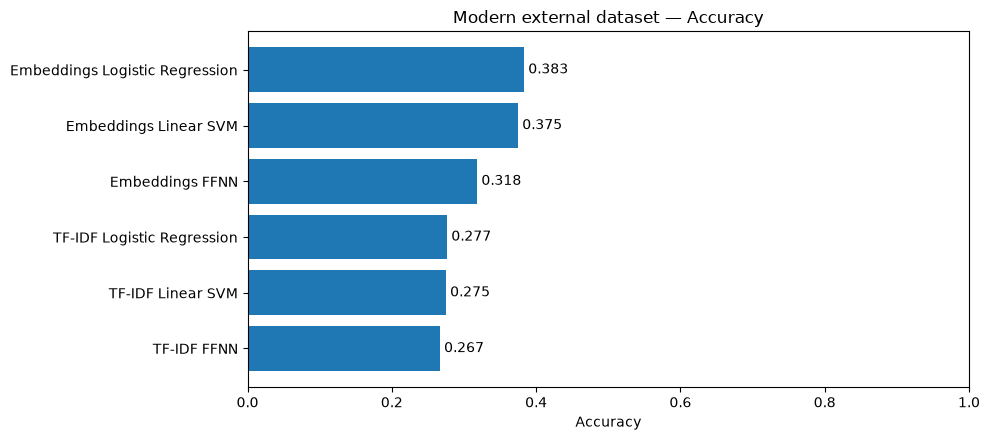

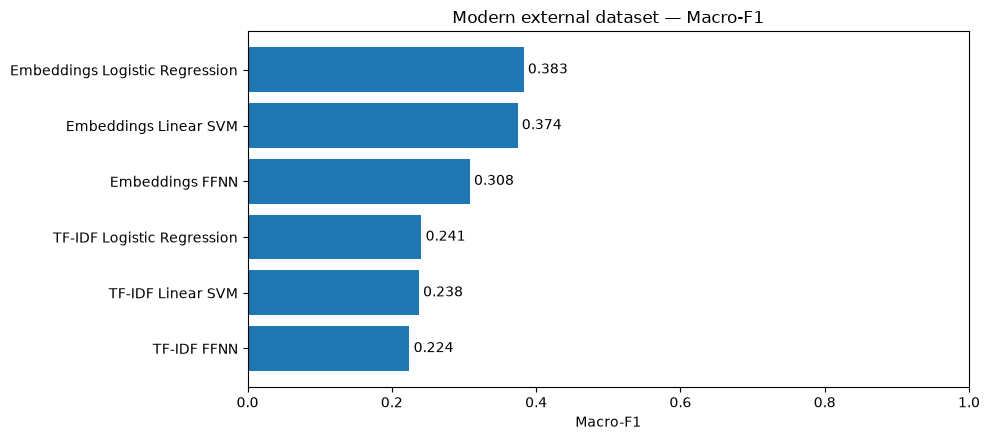

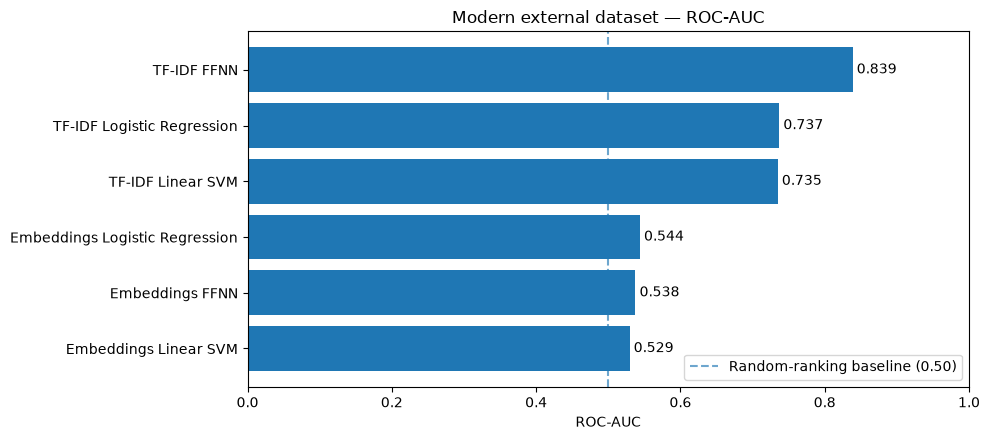

In [4]:
plot_metrics = [('accuracy', 'Accuracy'), ('macro_f1', 'Macro-F1'), ('roc_auc', 'ROC-AUC')]
for column, title in plot_metrics:
    ordered = metrics.sort_values(column, ascending=True)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bars = ax.barh(ordered['model'], ordered[column])
    ax.set_xlim(0, 1)
    ax.set_xlabel(title)
    ax.set_title(f'Modern external dataset — {title}')
    if column == 'roc_auc':
        ax.axvline(0.5, linestyle='--', alpha=0.65, label='Random-ranking baseline (0.50)')
        ax.legend(loc='lower right')
    ax.bar_label(bars, fmt='%.3f', padding=3)
    fig.tight_layout()
    plt.show()


## 5. Generator-specific AI recall and human false positives

For ChatGPT, Claude, and Gemini, the rate is **AI recall**. For human responses, the rate is **human false-positive rate** (lower is better). These are *different metrics* and should not be interpreted interchangeably.

generator,chatgpt,claude,gemini,human false-positive rate
model,,,,
Embeddings FFNN,0.1800,0.1533,0.0600,0.1200
Embeddings Linear SVM,0.2600,0.3200,0.1067,0.1867
Embeddings Logistic Regression,0.2933,0.3200,0.0933,0.1733
TF-IDF FFNN,0.0400,0.0267,0.0000,0.0000
TF-IDF Linear SVM,0.0133,0.0933,0.0000,0.0067
TF-IDF Logistic Regression,0.0267,0.0933,0.0000,0.0133


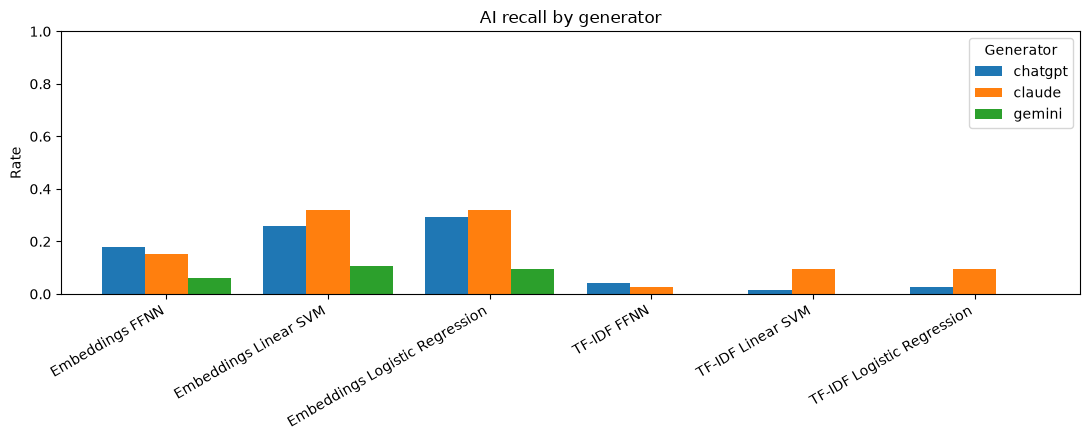

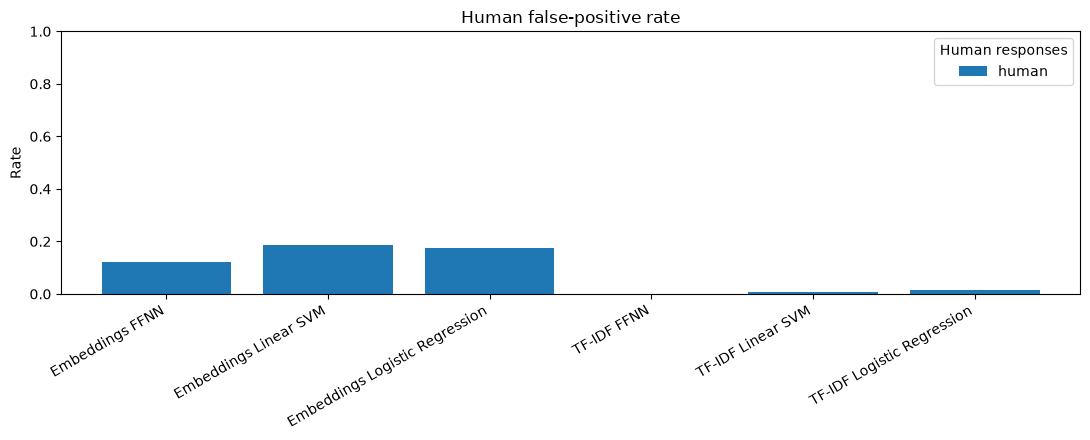

In [5]:
tfidf_gen = pd.read_csv(files['TF-IDF generator metrics'])
embedding_gen = pd.read_csv(files['Embeddings generator metrics'])
gen = pd.concat([tfidf_gen, embedding_gen], ignore_index=True)
expected_gen_cols = {'model', 'generator', 'n', 'metric', 'rate'}
assert expected_gen_cols.issubset(gen.columns), 'Missing generator-metric columns'
assert set(gen['model']) == set(metrics['model']), 'Generator CSVs do not contain all six models'
assert ((gen.loc[gen.generator.str.lower() == 'human', 'metric'] ==
         'human_false_positive_rate').all()), 'Human rate must be false-positive rate'
assert ((gen.loc[gen.generator.str.lower() != 'human', 'metric'] ==
         'ai_recall').all()), 'AI generator rate must be recall'

rates = gen.pivot(index='model', columns='generator', values='rate').reindex(metrics['model'])
display(rates.rename(columns={'human': 'human false-positive rate'}).round(4))

for generators, title in [(['chatgpt', 'claude', 'gemini'], 'AI recall by generator'),
                          (['human'], 'Human false-positive rate')]:
    available = [c for c in generators if c in rates.columns]
    if not available:
        continue
    ax = rates[available].plot(kind='bar', figsize=(11, 4.5), width=0.8)
    ax.set_title(title)
    ax.set_ylabel('Rate')
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
    ax.legend(title='Generator' if generators[0] != 'human' else 'Human responses')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()


## 6. ROC curves — all six trained models

Continuous scores are needed for these curves: probabilities for LR/FFNN, decision margins for Linear SVM. A margin does **not** represent a calibrated probability. We do not change any decision threshold here.

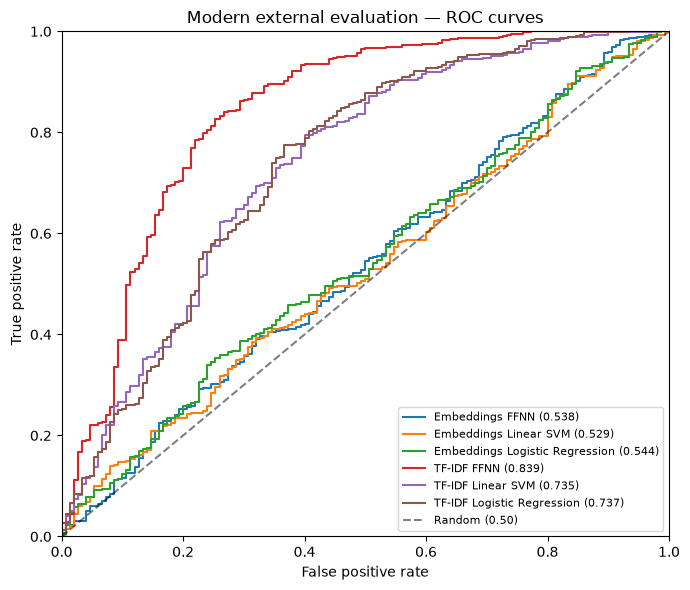

In [6]:
pred_files = [tfidf_pred, embedding_pred]
y_true = tfidf_pred['target'].to_numpy()
all_score_columns = {}
all_prediction_columns = {}
for df in pred_files:
    for col in df.columns:
        if col.endswith('_score'):
            name = col.removesuffix('_score')
            assert name not in all_score_columns, f'Duplicate score column: {name}'
            all_score_columns[name] = df[col].to_numpy(dtype=float)
        elif col.endswith('_prediction'):
            name = col.removesuffix('_prediction')
            assert name not in all_prediction_columns, f'Duplicate prediction column: {name}'
            all_prediction_columns[name] = df[col].to_numpy(dtype=int)

expected_keys = {name.lower().replace(' ', '_').replace('-', '_') for name in metrics['model']}
assert set(all_score_columns) == expected_keys, 'Missing or extra score columns'
assert set(all_prediction_columns) == expected_keys, 'Missing or extra prediction columns'

fig, ax = plt.subplots(figsize=(7, 6))
for name in metrics['model']:
    key = name.lower().replace(' ', '_').replace('-', '_')
    scores = all_score_columns[key]
    assert len(scores) == len(y_true) and np.isfinite(scores).all()
    observed_auc = roc_auc_score(y_true, scores)
    saved_auc = float(metrics.loc[metrics['model'] == name, 'roc_auc'].iloc[0])
    assert np.isclose(observed_auc, saved_auc, atol=1e-6),            f'{name}: ROC-AUC differs from exported metrics; rerun both evaluation exports'
    fpr, tpr, _ = roc_curve(y_true, scores)
    ax.plot(fpr, tpr, label=f'{name} ({observed_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (0.50)')
ax.set(xlabel='False positive rate', ylabel='True positive rate',
       title='Modern external evaluation — ROC curves', xlim=(0, 1), ylim=(0, 1))
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
plt.show()


## 7. Confusion matrices and per-class recall

Rows show the **actual** class; columns show the **predicted** class. Human = 0; AI = 1. These use the original predictions from the two evaluation notebooks, without any threshold changes.

Embeddings FFNN: human recall = 88.0%; AI recall = 13.1%


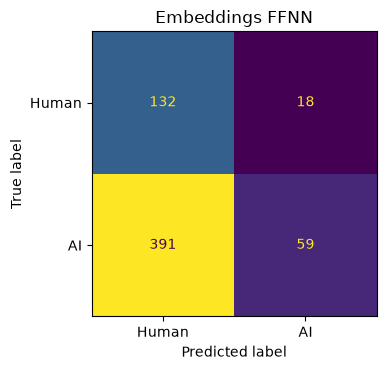

Embeddings Linear SVM: human recall = 81.3%; AI recall = 22.9%


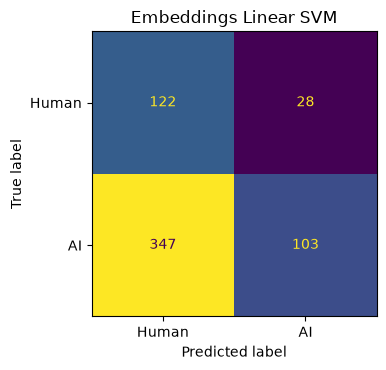

Embeddings Logistic Regression: human recall = 82.7%; AI recall = 23.6%


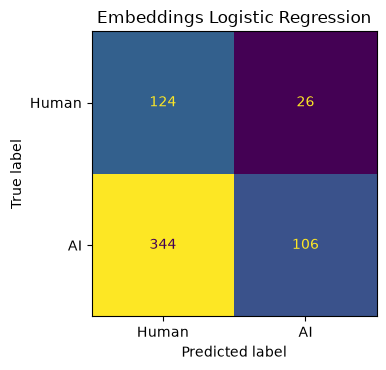

TF-IDF FFNN: human recall = 100.0%; AI recall = 2.2%


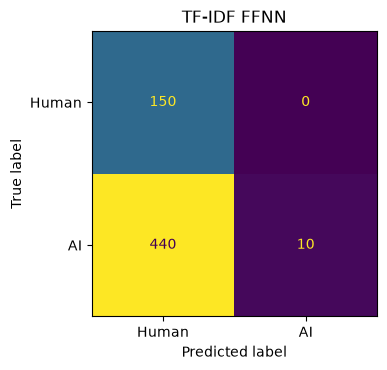

TF-IDF Linear SVM: human recall = 99.3%; AI recall = 3.6%


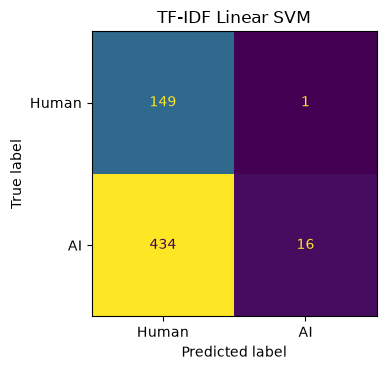

TF-IDF Logistic Regression: human recall = 98.7%; AI recall = 4.0%


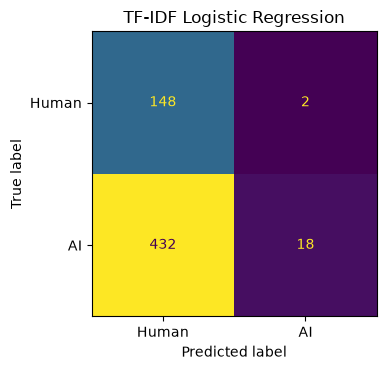

In [7]:
for name in metrics['model']:
    key = name.lower().replace(' ', '_').replace('-', '_')
    pred = all_prediction_columns[key]
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    human_recall = cm[0, 0] / cm[0].sum()
    ai_recall = cm[1, 1] / cm[1].sum()
    print(f'{name}: human recall = {human_recall:.1%}; AI recall = {ai_recall:.1%}')
    fig, ax = plt.subplots(figsize=(4.5, 3.8))
    ConfusionMatrixDisplay(cm, display_labels=['Human', 'AI']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
    fig.tight_layout()
    plt.show()


## 8. Export one combined results table

These files are derived only from the saved external evaluation exports. Do not use this same external test set repeatedly to select thresholds or tune models.

In [8]:
metrics.to_csv(RESULTS_DIR / 'modern_six_model_comparison.csv', index=False)
gen.to_csv(RESULTS_DIR / 'modern_six_model_generator_metrics.csv', index=False)
print('Saved:')
print(RESULTS_DIR / 'modern_six_model_comparison.csv')
print(RESULTS_DIR / 'modern_six_model_generator_metrics.csv')


Saved:
/Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation/modern_six_model_comparison.csv
/Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation/modern_six_model_generator_metrics.csv
